# Telco Customer Churn Prediction
This notebook covers the complete data science pipeline for predicting customer churn using the Telco Customer Churn dataset from Kaggle.
The goal is to build a binary classification model to predict whether a customer will churn (`Yes`) or not (`No`).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pickle



## Part 1: Data Acquisition & Preprocessing
### 1. Dataset Selection
The Telco Customer Churn dataset contains information about a fictional telco company that provided home phone and Internet services to 7043 customers in California in Q3. It indicates which customers have left, stayed, or signed up for their service. The target variable is `Churn`.

### 2. Data Loading

In [2]:
# Load the dataset
df = pd.read_csv('data/Telco-Customer-Churn.csv')

# Display first few rows
display(df.head())

# Display dataset info
display(df.info())

# Display summary statistics
display(df.describe())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


None

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


### 3. Exploratory Data Analysis (EDA)

In [3]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

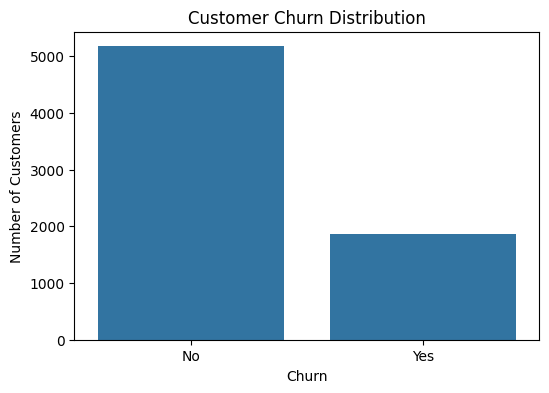

In [4]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

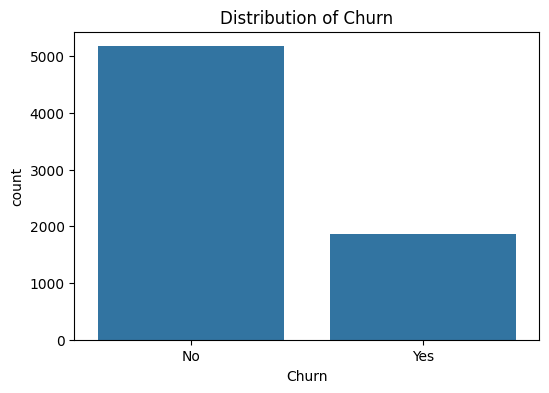

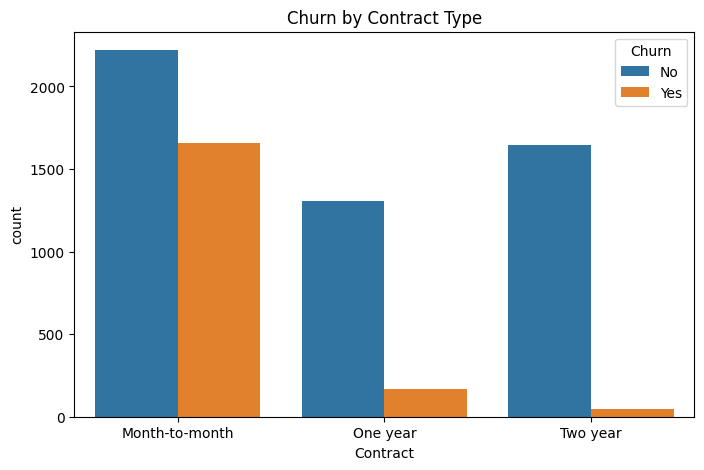

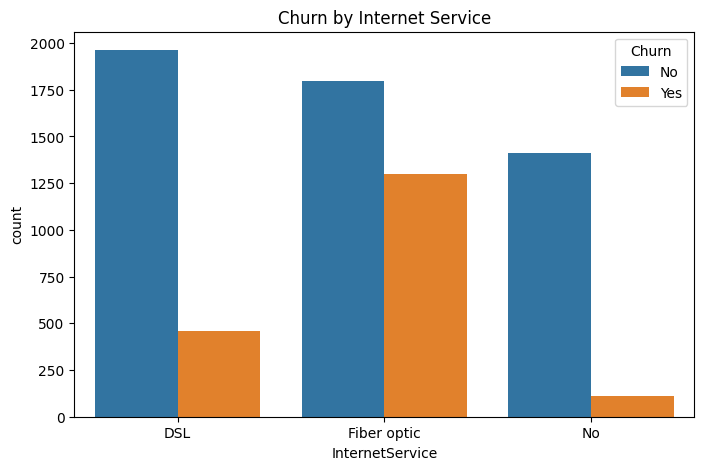

In [5]:
# Distribution of target variable
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn')
plt.title('Distribution of Churn')
plt.show()

# Churn rate by Contract type
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Churn by Contract Type')
plt.show()

# Churn rate by Internet Service
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='InternetService', hue='Churn')
plt.title('Churn by Internet Service')
plt.show()

C:\Users\bhakt\AppData\Local\Temp\ipykernel_16028\1968660407.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  temp_df['TotalCharges'].fillna(0, inplace=True)


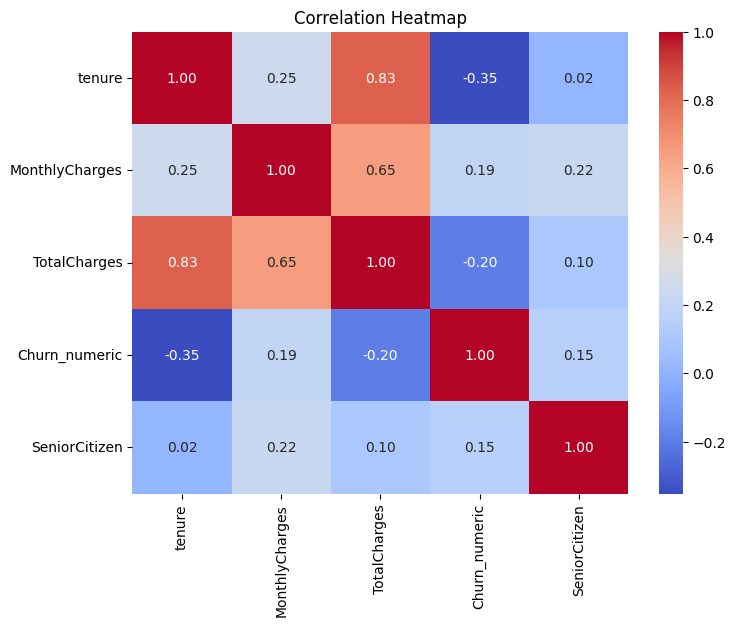

In [6]:
# Correlation heatmap of numeric features
# First convert TotalCharges to numeric for EDA
temp_df = df.copy()
temp_df['TotalCharges'] = pd.to_numeric(temp_df['TotalCharges'], errors='coerce')
temp_df['TotalCharges'].fillna(0, inplace=True)
temp_df['Churn_numeric'] = temp_df['Churn'].map({'Yes': 1, 'No': 0})

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_numeric', 'SeniorCitizen']
plt.figure(figsize=(8, 6))
sns.heatmap(temp_df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

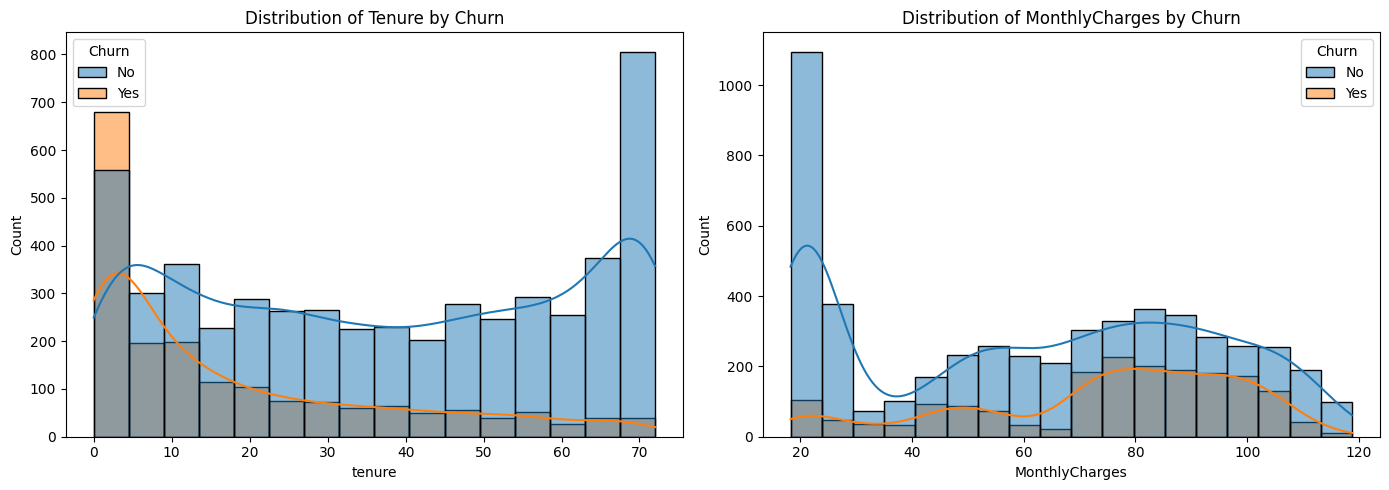

In [7]:
# Distribution of tenure and MonthlyCharges by Churn
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x='tenure', hue='Churn', kde=True, ax=axes[0])
axes[0].set_title('Distribution of Tenure by Churn')

sns.histplot(data=df, x='MonthlyCharges', hue='Churn', kde=True, ax=axes[1])
axes[1].set_title('Distribution of MonthlyCharges by Churn')

plt.tight_layout()
plt.show()

**Summary of EDA Findings:**
- The dataset is imbalanced, with fewer churned customers than retained ones.
- Customers with month-to-month contracts have a significantly higher churn rate compared to those with one- or two-year contracts.
- Customers with Fiber optic internet service show a higher churn rate compared to DSL or no internet service.
- Churn is negatively correlated with tenure; newer customers are more likely to churn.
- Higher monthly charges are somewhat associated with higher churn.

### 4. Data Preprocessing

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Drop customerID
df_clean = df.drop('customerID', axis=1)

# Convert TotalCharges to numeric, fill NaN with 0
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

# Store column info for Streamlit App
column_info = {
    'gender': ['Female', 'Male'],
    'SeniorCitizen': [0, 1],
    'Partner': ['Yes', 'No'],
    'Dependents': ['Yes', 'No'],
    'tenure': {'min': 0, 'max': 72, 'type': 'numeric'},
    'PhoneService': ['Yes', 'No'],
    'MultipleLines': ['No phone service', 'No', 'Yes'],
    'InternetService': ['DSL', 'Fiber optic', 'No'],
    'OnlineSecurity': ['No', 'Yes', 'No internet service'],
    'OnlineBackup': ['No', 'Yes', 'No internet service'],
    'DeviceProtection': ['No', 'Yes', 'No internet service'],
    'TechSupport': ['No', 'Yes', 'No internet service'],
    'StreamingTV': ['No', 'Yes', 'No internet service'],
    'StreamingMovies': ['No', 'Yes', 'No internet service'],
    'Contract': ['Month-to-month', 'One year', 'Two year'],
    'PaperlessBilling': ['Yes', 'No'],
    'PaymentMethod': ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)'],
    'MonthlyCharges': {'min': 18.25, 'max': 118.75, 'type': 'numeric'},
    'TotalCharges': {'min': 0, 'max': 8684.8, 'type': 'numeric'}
}
with open('models/column_info.pkl', 'wb') as f:
    pickle.dump(column_info, f)

# Encode Churn to 0/1
df_clean['Churn'] = df_clean['Churn'].map({'Yes': 1, 'No': 0})

# Identify binary and multi-class categorical columns
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
multi_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 
              'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 
              'Contract', 'PaymentMethod']

# Label encode binary columns manually to maintain control and save mappings
label_encoders = {}
for col in binary_cols:
    mapping = {val: i for i, val in enumerate(df_clean[col].unique())}
    df_clean[col] = df_clean[col].map(mapping)
    label_encoders[col] = mapping

with open('models/label_encoders.pkl', 'wb') as f:
    pickle.dump(label_encoders, f)

# One-hot encode multi-category columns
df_encoded = pd.get_dummies(df_clean, columns=multi_cols, drop_first=True)

# Separate features and target
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

# Feature scaling
scaler = StandardScaler()
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
X[num_cols] = scaler.fit_transform(X[num_cols])

# Save feature names and scaler
feature_names = list(X.columns)
with open('models/feature_names.pkl', 'wb') as f:
    pickle.dump(feature_names, f)
joblib.dump(scaler, 'models/scaler.joblib')

['models/scaler.joblib']

### 5. Train/Test Split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (5634, 30)
Testing set shape: (1409, 30)


## Part 2: Model Implementation & Evaluation

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import GridSearchCV, cross_val_score

# 6. Model Implementation & 7. Model Training
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'KNN': KNeighborsClassifier()
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model

C:\Users\bhakt\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



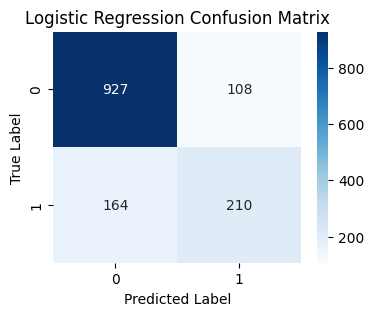

--- Random Forest ---
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.64      0.51      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



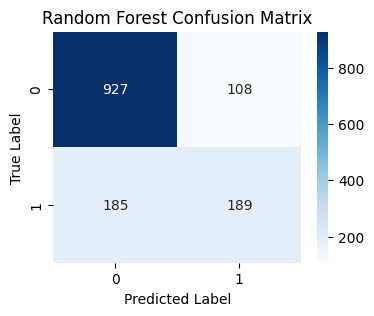

--- SVM ---
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1035
           1       0.65      0.48      0.55       374

    accuracy                           0.79      1409
   macro avg       0.74      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



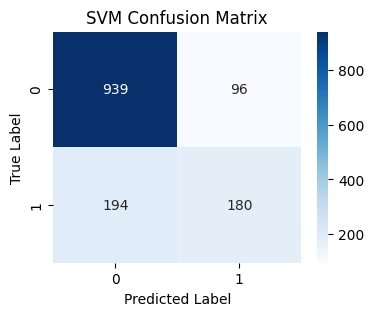

--- KNN ---
              precision    recall  f1-score   support

           0       0.84      0.84      0.84      1035
           1       0.55      0.55      0.55       374

    accuracy                           0.76      1409
   macro avg       0.70      0.70      0.70      1409
weighted avg       0.76      0.76      0.76      1409



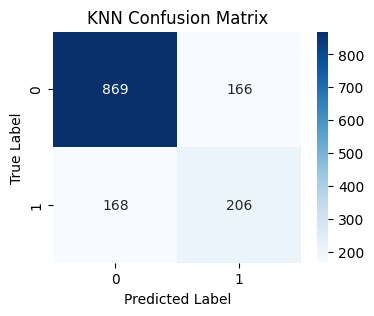

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.806955,0.660377,0.561497,0.606936
1,Random Forest,0.792051,0.636364,0.505348,0.563338
2,SVM,0.794180,0.652174,0.481283,0.553846
3,KNN,0.762952,0.553763,0.550802,0.552279


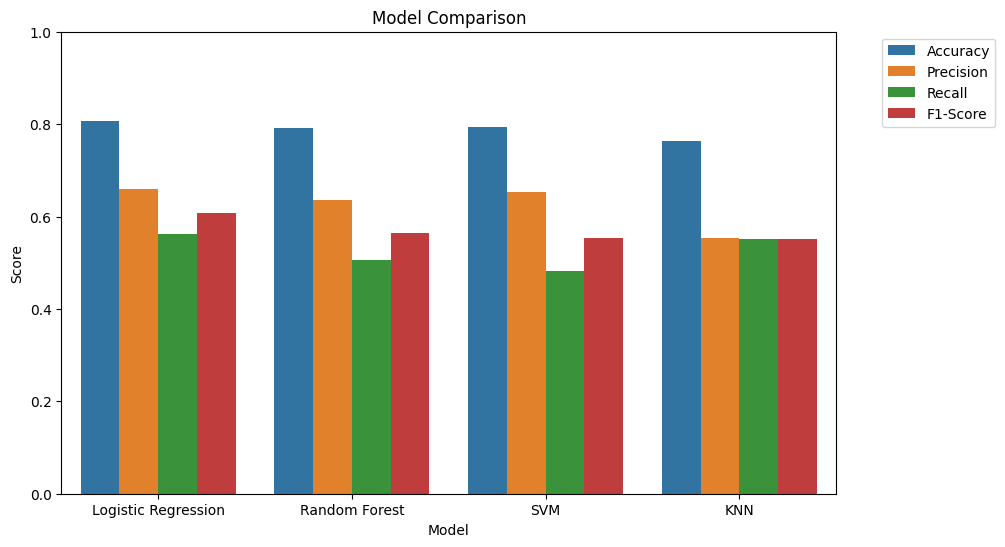

In [11]:
# 8. Model Evaluation
metrics = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    metrics.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })
    
    print(f"--- {name} ---")
    print(classification_report(y_test, y_pred))
    
    plt.figure(figsize=(4, 3))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title(f'{name} Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

metrics_df = pd.DataFrame(metrics)
display(metrics_df)

# Comparison Bar Chart
metrics_melted = pd.melt(metrics_df, id_vars="Model", var_name="Metric", value_name="Score")
plt.figure(figsize=(10, 6))
sns.barplot(data=metrics_melted, x='Model', y='Score', hue='Metric')
plt.title('Model Comparison')
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

### 9. Hyperparameter Tuning & Cross-Validation

In [12]:
# 5-Fold Cross-Validation on all 4 models
print("5-Fold Cross Validation Results (Accuracy):")
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    print(f"{name}: Mean = {scores.mean():.4f}, Std = {scores.std():.4f}")

# GridSearchCV for Random Forest
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5, 10]
}

rf = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

print(f"\nBest Parameters for Random Forest: {grid_search.best_params_}")
print(f"Best CV Score: {grid_search.best_score_:.4f}")

# Retrain and evaluate best model
best_rf = grid_search.best_estimator_
y_pred_best = best_rf.predict(X_test)

print("\n--- Optimized Random Forest ---")
print(classification_report(y_test, y_pred_best))

5-Fold Cross Validation Results (Accuracy):
Logistic Regression: Mean = 0.8046, Std = 0.0144
Random Forest: Mean = 0.7838, Std = 0.0133


C:\Users\bhakt\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\bhakt\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\bhakt\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\bhakt\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probabilit

SVM: Mean = 0.8032, Std = 0.0126
KNN: Mean = 0.7632, Std = 0.0101
Fitting 3 folds for each of 36 candidates, totalling 108 fits

Best Parameters for Random Forest: {'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 200}
Best CV Score: 0.8049

--- Optimized Random Forest ---
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.66      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



### 10. Save Models

In [13]:
# Save all trained models
joblib.dump(trained_models['Logistic Regression'], 'models/logistic_regression.joblib')
joblib.dump(best_rf, 'models/random_forest.joblib')
joblib.dump(trained_models['SVM'], 'models/svm.joblib')
joblib.dump(trained_models['KNN'], 'models/knn.joblib')

print("All models, scalers, and encoders have been successfully saved to the 'models/' directory.")

All models, scalers, and encoders have been successfully saved to the 'models/' directory.
